<center><h1>HW6</h1></center>

Name: Xiaoman Niu
<br>
Github Username: xiaomann339
<br>
USC ID: 6306697960

## 1. Tree-Based Methods

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

### (a) Download the APS Failure data

In [2]:
train = pd.read_csv("../data/aps_failure_training_set.csv", skiprows=20, na_values="na") #first 20 lines are not data
test  = pd.read_csv("../data/aps_failure_test_set.csv",     skiprows=20, na_values="na")

X_train1 = train.drop(columns="class")
y_train     = (train["class"] == "pos").astype(int)
X_test1  = test.drop(columns="class")
y_test      = (test["class"] == "pos").astype(int)

print("train:", train.shape, " test:", test.shape)

train: (60000, 171)  test: (16000, 171)


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

 Common techniques for missing data:
1. **Deletion** – drop rows (listwise deletion) or drop columns with too many missing values.
2. **Simple imputation** – replace with the column mean / median / mode or a constant.
3. **Model-based imputation** – KNN imputation, regression imputation, MICE (iterative imputation), MissForest.
4. **Missing indicator** – add a binary flag marking which values were missing.
5. **Models that handle NaN natively** – e.g. XGBoost learns a default split direction for missing values.

In [3]:
miss_col = X_train1.isna().mean().sort_values(ascending=False)
print(f"rows with missing value: {X_train1.isna().any(axis=1).mean():.2%}")
print(f"overall fraction of missing cells:     {X_train1.isna().values.mean():.2%}")
print(f"features with missing values: {(miss_col > 0).sum()} / {X_train1.shape[1]}")
print("top-5 features by missing rate:", miss_col.head().round(3).to_dict())

rows with missing value: 99.02%
overall fraction of missing cells:     8.33%
features with missing values: 169 / 170
top-5 features by missing rate: {'br_000': 0.821, 'bq_000': 0.812, 'bp_000': 0.796, 'bo_000': 0.772, 'cr_000': 0.772}


In [4]:
skew = X_train1.skew() #check the distribution of data
print(f"mean > median: {(X_train1.mean() > X_train1.median()).sum()} / {X_train1.shape[1]}")
print(f"skewness > 1:  {(skew > 1).sum()} / {X_train1.shape[1]}   (median skewness = {skew.median():.1f})")

mean > median: 169 / 170
skewness > 1:  163 / 170   (median skewness = 17.5)


About 99% of the rows have at least one missing value, so deleting rows would discard almost the whole data set.
The features are counters/histograms and are highly right-skewed: 169/170 features have mean > median and 163/170 have skewness > 1.
The mean is pulled up by extreme values, so we use **median imputation**, which is robust to outliers.
Following footnote 1, the training set is imputed with training-set medians and the test set with test-set medians.

In [5]:
from sklearn.impute import SimpleImputer
X_train = pd.DataFrame(SimpleImputer(strategy = 'median').fit_transform(X_train1), columns = X_train1.columns)
X_test = pd.DataFrame(SimpleImputer(strategy = 'median').fit_transform(X_test1), columns = X_test1.columns)

#### (ii) Calculate the coefficient of variation

In [6]:
cv = (X_train.std(ddof = 1) / X_train.mean()).sort_values(ascending = False)
cells = [f"{f}: {v:8.3f}" for f, v in cv.items()] # print all 170 CVs compactly: 5 per line
print("\n".join("   ".join(cells[i:i + 5]) for i in range(0, len(cells), 5)))

cf_000:  244.888   co_000:  244.507   ad_000:  244.323   cs_009:  237.931   dh_000:  123.216
dj_000:  117.494   ag_000:   92.918   as_000:   87.332   ay_009:   84.734   ak_000:   80.425
az_009:   77.839   ch_000:   77.454   au_000:   68.883   cr_000:   58.078   ay_001:   52.825
df_000:   52.293   dz_000:   51.332   ef_000:   49.367   cs_008:   48.102   aj_000:   44.266
eg_000:   42.482   dl_000:   39.739   ay_002:   39.249   dg_000:   38.486   ay_000:   37.428
dk_000:   37.039   cy_000:   36.601   dm_000:   36.261   ag_001:   35.249   ea_000:   34.947
cn_009:   34.272   ay_004:   33.752   ag_009:   33.358   da_000:   29.368   ay_003:   28.735
cn_000:   26.336   ae_000:   24.200   at_000:   23.708   az_008:   22.680   dq_000:   22.030
af_000:   19.471   ai_000:   18.204   ag_002:   17.566   az_007:   16.229   cl_000:   14.971
cz_000:   14.506   cp_000:   13.933   az_002:   13.272   ay_005:   12.525   di_000:   11.826
ar_000:   11.354   cn_001:   11.263   cj_000:   11.070   ab_000:   10.

#### (iii) Plot a correlation matrix

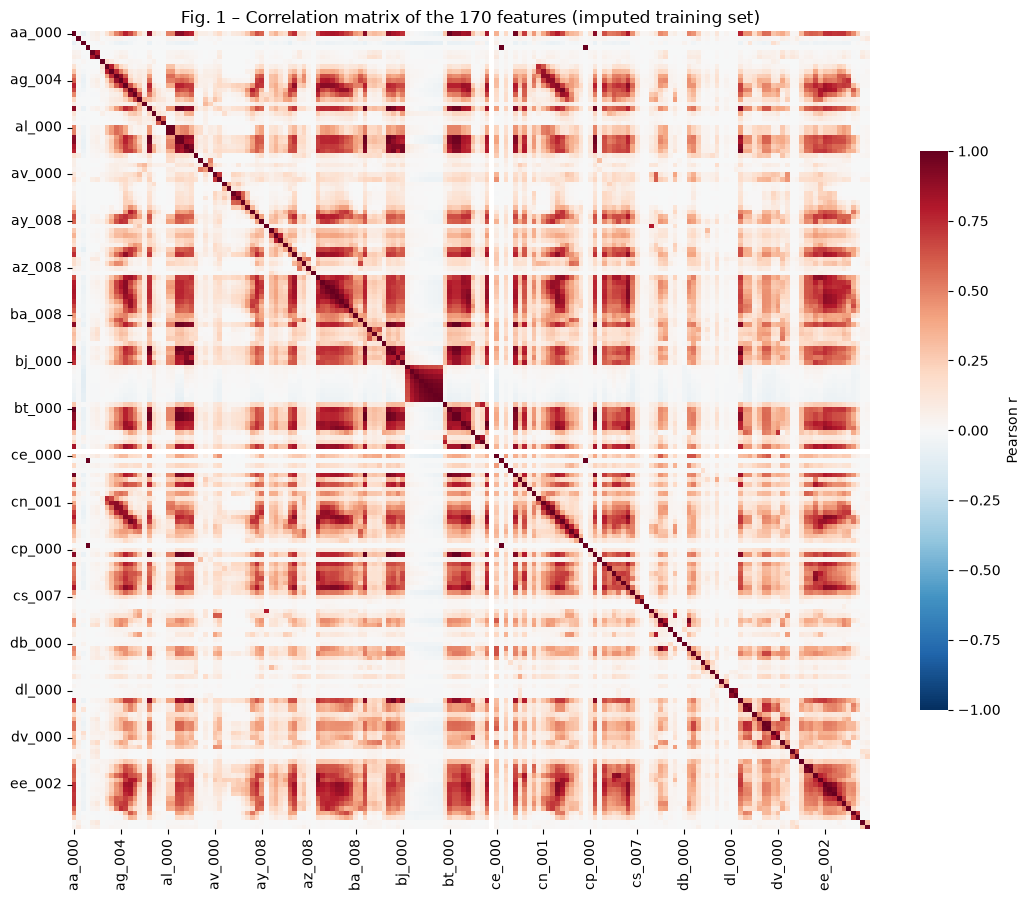

In [7]:
corr = X_train.corr()
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            xticklabels=10, yticklabels=10,
            cbar_kws={"shrink": .7, "label": "Pearson r"}, ax=ax)
ax.set_title("Fig. 1 – Correlation matrix of the 170 features (imputed training set)")
plt.tight_layout(); plt.show()

Observations:
- Almost all correlations are positive.
- The dark square block (`bk_000`–`br_000`) is a group of features that are highly correlated with each other  but nearly uncorrelated with all other features. These are also the features with the most missing values.
- The diagonal band between the `ag_*` and `cn_*` histograms shows that corresponding bins of these two histograms are strongly correlated .
- Many features are highly correlated, so the feature set contains a lot of redundancy.

#### (iv) Make scatter plots and box plots

top 13 cv features ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


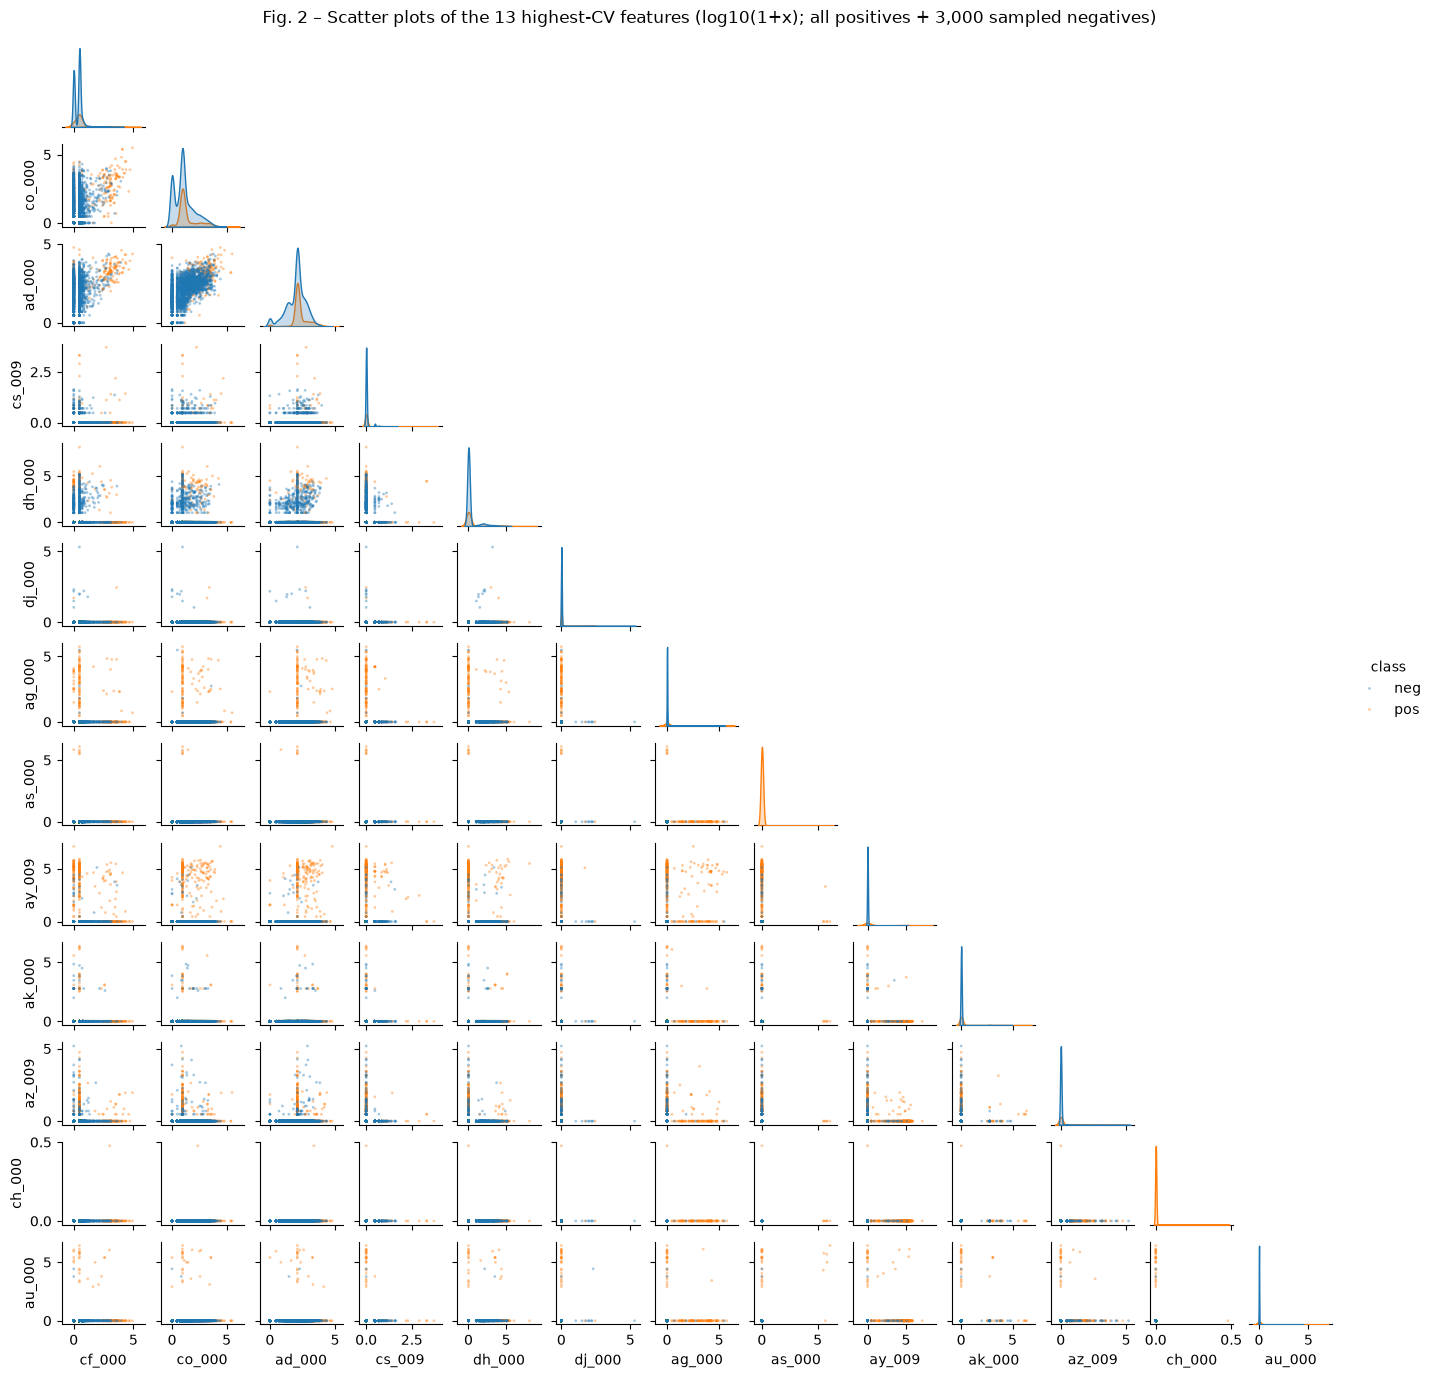

In [8]:
k = int(np.floor(np.sqrt(170)))
top = cv.index[:k].tolist()
print(f"top {k} cv features", top)

df1 = np.log10(1+X_train[top])
df1["class"] = train["class"].values
sample = pd.concat([df1[df1["class"] == "pos"],
                    df1[df1["class"] == "neg"].sample(3000, random_state = SEED)]) #class is very imbalanced , we sample neg to illustrate

g = sns.pairplot(sample, vars=top, hue="class", hue_order=["neg", "pos"], corner=True,
                 palette={"neg": "tab:blue", "pos": "tab:orange"},
                 plot_kws={"s": 4, "alpha": .4, "linewidth": 0}, diag_kind="kde", height=1.05)
g.fig.suptitle("Fig. 2 – Scatter plots of the 13 highest-CV features "
               "(log10(1+x); all positives + 3,000 sampled negatives)", y=1.01)
plt.show()

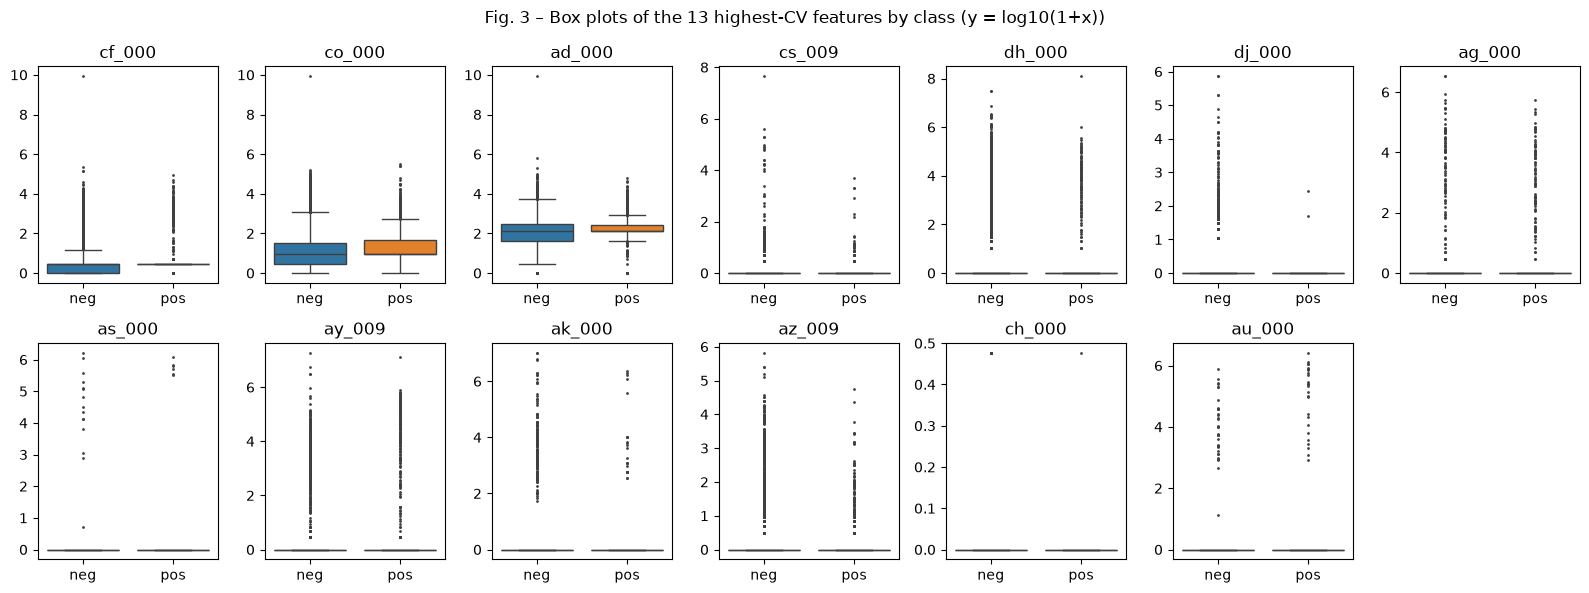

In [9]:
fig, axes = plt.subplots(2, 7, figsize=(16, 6))
for ax, f in zip(axes.ravel(), top):
    sns.boxplot(x=train["class"], y=np.log10(1 + X_train[f]), order=["neg", "pos"],
                hue=train["class"], palette={"neg": "tab:blue", "pos": "tab:orange"},
                fliersize=1, ax=ax, legend=False)
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("")
axes.ravel()[-1].axis("off")
fig.suptitle("Fig. 3 – Box plots of the 13 highest-CV features by class (y = log10(1+x))")
plt.tight_layout(); plt.show()

Can we draw conclusions about significance from the scatter plots alone? **No.**

The plots only give hints. For some features (e.g. `ay_009`, `az_009`, `ag_000`, `au_000`), non-zero values appear relatively more often among positive trucks, while others (e.g. `cs_009`, `dh_000`, `dj_000`) look similar in both classes. Most of these features are 0 for the vast majority of trucks in both classes, so most box plots collapse to a line at 0.

The plots also depend on preprocessing. The negatives were down-sampled, which exaggerates the visual share of positives. Median imputation fills the many missing positives of `cf_000`/`co_000`/`ad_000` with values typical of negatives, which is why the positive boxes are compressed.

Scatter plots show only pairwise relationships, ignore the other features and their correlations, and give no measure of uncertainty (no test statistic or p-value). Significance must be assessed with a formal test or a fitted model. Moreover, a high CV is mainly caused by a few extreme values, so it does not indicate usefulness for classification.

#### (v) Is this data set imbalanced?

In [10]:
print(train["class"].value_counts().to_string())
print(f"pos rate = {y_train.mean():.2%}  "
      f"neg : pos = {(y_train == 0).sum() / (y_train == 1).sum():.0f} :1")
print(f"test set: {y_test.sum()} pos / {(y_test == 0).sum()} neg  (positive rate = {y_test.mean():.2%})")

class
neg    59000
pos     1000
pos rate = 1.67%  neg : pos = 59 :1
test set: 375 pos / 15625 neg  (positive rate = 2.34%)


The training set has 59,000 negatives and 1,000 positives (1.67%, ratio 59:1), so the data set is **highly imbalanced**.
Always predicting "neg" already gives 98.3% accuracy but catches no failures, so accuracy alone is misleading. 

### (c) Train a random forest

In [11]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators = 200, oob_score = True, n_jobs = -1, random_state = SEED)
rf.fit(X_train,y_train)
print(f"OOB error estimate = {1 - rf.oob_score_:.5f}")

OOB error estimate = 0.00583


In [12]:
from sklearn.metrics import confusion_matrix
oob_pred = (rf.oob_decision_function_[:, 1] >= 0.5).astype(int)
print(confusion_matrix(y_train, oob_pred))

[[58924    76]
 [  273   727]]


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, roc_curve

### Helper: evaluation on training and test sets
results = {}

def evaluate(model, name, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    rows = {}
    for i, (split, X, y) in enumerate([("Train", X_tr, y_tr), ("Test", X_te, y_te)]):
        prob = model.predict_proba(X)[:, 1]
        pred = (prob >= 0.5).astype(int)
        cm = confusion_matrix(y, pred)
        ConfusionMatrixDisplay(cm, display_labels=["neg", "pos"]).plot(
            ax=axes[i], colorbar=False, values_format="d")
        axes[i].set_title(f"{name} – {split} confusion matrix")
        fpr, tpr, _ = roc_curve(y, prob)
        auc = roc_auc_score(y, prob)
        axes[2].plot(fpr, tpr, label=f"{split} (AUC = {auc:.4f})")
        tn, fp, fn, tp = cm.ravel()
        rows[split] = {"TN": tn, "FP": fp, "FN": fn, "TP": tp, "AUC": round(auc, 4),
                       "Misclassification": round((fp + fn) / len(y), 5),
                       "Cost": 10 * fp + 500 * fn}
    axes[2].plot([0, 1], [0, 1], "k--", lw=.8)
    axes[2].set(xlabel="False positive rate", ylabel="True positive rate", title=f"{name} – ROC")
    axes[2].legend(loc="lower right")
    plt.tight_layout(); plt.show()
    df = pd.DataFrame(rows).T
    results[name] = df
    print(df.to_string())
    return df

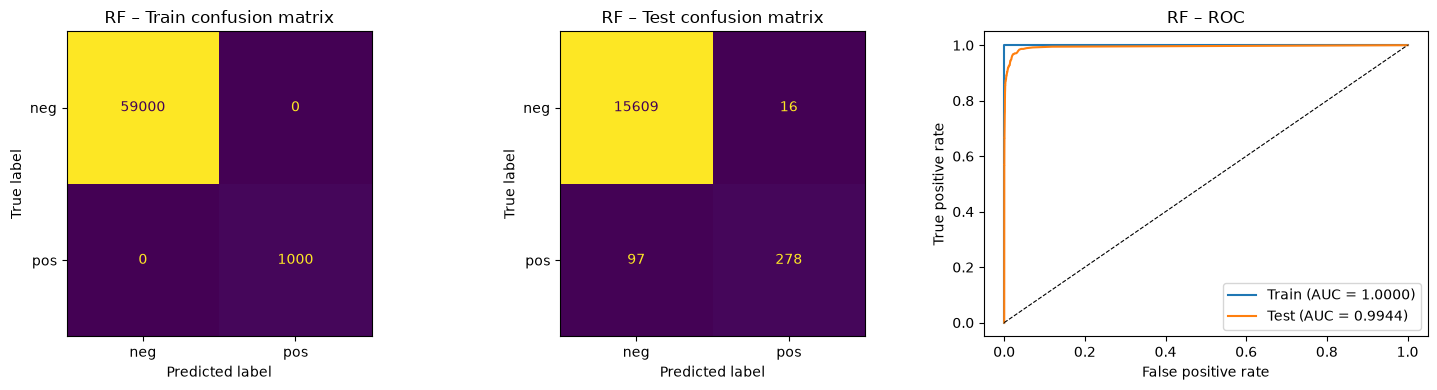

            TN    FP    FN      TP     AUC  Misclassification     Cost
Train  59000.0   0.0   0.0  1000.0  1.0000            0.00000      0.0
Test   15609.0  16.0  97.0   278.0  0.9944            0.00706  48660.0

OOB error estimate = 0.00583   |   Test error = 0.00706


In [14]:
rf_res = evaluate(rf, "RF")
print(f"\nOOB error estimate = {1 - rf.oob_score_:.5f}   |   "
      f"Test error = {rf_res.loc['Test', 'Misclassification']:.5f}")

**Discussion.**
- The training set is fit perfectly (error 0, AUC 1.0) because fully grown trees memorize the training data, so the training error is not a useful estimate.
- **The OOB error (≈0.0058) is close to the test error (≈0.0071)** and far more realistic than the training error. Each sample is evaluated only by trees that did not see it, so OOB works like built-in cross-validation.
- The OOB error is slightly lower mainly because the test set has a higher positive rate (2.34% vs 1.67%) and almost all errors are on positives. The per-class error rates are similar: about 27% of positives are missed in OOB (273/1000) and 26% on the test set (97/375).

### (d) Research class imbalance in random forest

Research Ways to handle class imbalance in random forests:
- **Weighted RF**: give the minority class a larger weight in the Gini criterion and in the leaf votes.
- **Balanced RF**: grow each tree on a bootstrap sample in which the majority class is down-sampled so that both classes are equally represented (`BalancedRandomForestClassifier`).
- Re-sampling the whole training set (over-/under-sampling, SMOTE) and moving the decision threshold.

We use the **Balanced Random Forest**. With fully grown trees almost every leaf is pure, so class weights barely change the leaf votes. Down-sampling changes the data every tree sees, so it compensates for the imbalance much more effectively.

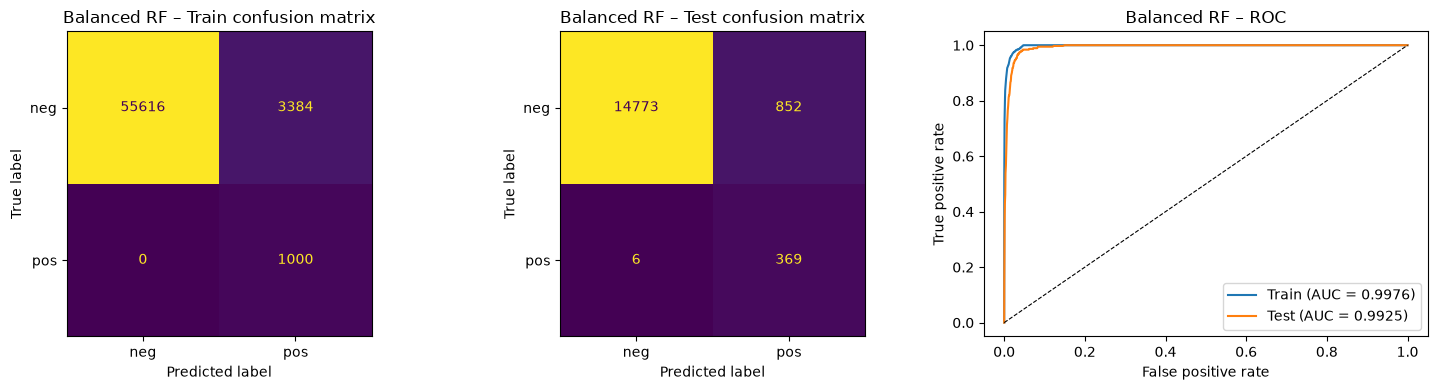

            TN      FP   FN      TP     AUC  Misclassification     Cost
Train  55616.0  3384.0  0.0  1000.0  0.9976            0.05640  33840.0
Test   14773.0   852.0  6.0   369.0  0.9925            0.05362  11520.0

oob error estimate = 0.04605     test error = 0.05362


In [15]:
from imblearn.ensemble import BalancedRandomForestClassifier

brf = BalancedRandomForestClassifier(n_estimators = 200, sampling_strategy = "auto", replacement = False,
                                     bootstrap = True, oob_score =True, n_jobs = -1, random_state =SEED)
brf.fit(X_train,y_train)
brf_res = evaluate(brf,"Balanced RF")
print(f"\noob error estimate = { 1 - brf.oob_score_:.5f}     "
      f"test error = {brf_res.loc['Test', 'Misclassification']:.5f}")


**Comparison with 1(c) (test set).**

| | RF (1c) | Balanced RF (1d) |
|---|---|---|
| Missed failures (FN) | 97 | **6** |
| False alarms (FP) | **16** | 852 |
| Misclassification | **0.00706** | 0.05362 |
| AUC | 0.9944 | 0.9925 |
| Scania cost | 48,660 | **11,520** |

- **FN drops:** with 59:1 imbalance, a plain RF favors the majority class to keep accuracy high. After down-sampling, every tree sees a 1:1 ratio, so positives are no longer neglected. On the test set FN falls from 97 to 6 (recall 74% → 98%), and on the training set FN = 0 because every tree uses all 1,000 positives.
- **overall error rises:** each tree effectively assumes a 50% prior for failures, so the 0.5 threshold becomes far more lenient, and the decision boundary shifts toward the negative class. Many negatives near the boundary are now labeled positive (FP 16 → 852). Negatives outnumber positives 42:1 in the test set, so this dominates the misclassification, and both the OOB error (0.00583 → 0.04605) and the test error (0.00706 → 0.05362) increase.
- **cost drops:** the AUC is almost unchanged, so the ranking ability is similar and mainly the operating point moved. Since a missed failure costs 50× a false alarm, this trade-off is very favorable: the cost falls from 48,660 to 11,520, close to the IDA 2016 top contestants (9,920–11,480).
- The OOB error still approximates the test error reasonably well.

### (e) XGBoost and Model Trees

In [16]:
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV

As clarified by the instructors on the course forum, standard XGBoost with L1 regularization is sufficient; a separate logistic-regression model tree is not required. We use boosted trees trained with the **logistic loss** (`objective="binary:logistic"`) and an **L1 penalty α on the leaf weights** (`reg_alpha`); XGBoost's default L2 penalty (`reg_lambda=1`) is kept. Other hyperparameters are fixed at common values (`max_depth=6`, `learning_rate=0.1`, `n_estimators=200`).
We choose α by **5-fold stratified cross-validation** (LOOCV would need 60,000 fits). Since accuracy is uninformative under this imbalance, α is selected by AUC. The CV misclassification of the chosen α is then compared with the test error.

In [17]:
cv5 = StratifiedKFold(n_splits = 5, shuffle = True, random_state = SEED)
xgb_params = dict(n_estimators = 200, max_depth = 6, learning_rate = 0.1, tree_method = "hist",
                  objective = "binary:logistic", eval_metric = "logloss", n_jobs = -1, random_state = SEED)
alphas = [0.01, 0.1, 1, 10, 100]

gs_xgb = GridSearchCV(XGBClassifier(**xgb_params), {"reg_alpha":alphas}, cv = cv5,
                      scoring = {"auc":"roc_auc", "acc":"accuracy"}, refit = "auc")

gs_xgb.fit(X_train, y_train)

cvt = pd.DataFrame({"alpha": alphas, "cv auc":gs_xgb.cv_results_["mean_test_auc"].round(5),
                    "cv error": (1 - gs_xgb.cv_results_["mean_test_acc"]).round(5)})
print(cvt.to_string(index = False))
xgb_cv_err = 1 - gs_xgb.cv_results_["mean_test_acc"][gs_xgb.best_index_]
print(f"\nbest alpha = {gs_xgb.best_params_['reg_alpha']}")

 alpha  cv auc  cv error
  0.01 0.98931   0.00538
  0.10 0.98934   0.00552
  1.00 0.98947   0.00538
 10.00 0.98929   0.00712
100.00 0.98200   0.01098

best alpha = 1


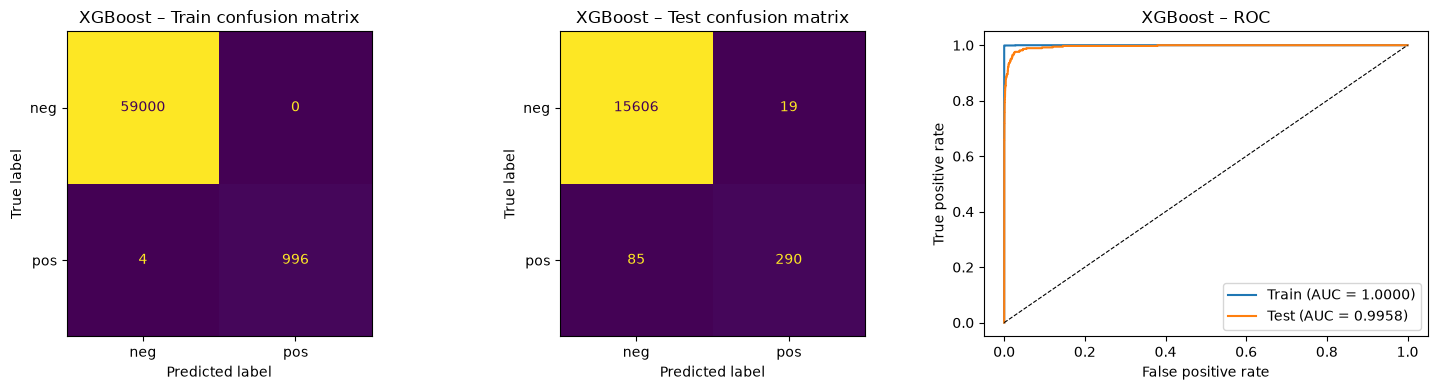

            TN    FP    FN     TP     AUC  Misclassification     Cost
Train  59000.0   0.0   4.0  996.0  1.0000            0.00007   2000.0
Test   15606.0  19.0  85.0  290.0  0.9958            0.00650  42690.0

5-fold CV error = 0.00538   |   Test error = 0.00650


In [18]:
xgb_res = evaluate(gs_xgb.best_estimator_, "XGBoost")
print(f"\n5-fold CV error = {xgb_cv_err:.5f}   |   "
      f"Test error = {xgb_res.loc['Test', 'Misclassification']:.5f}")

**Discussion.**
- CV selects α = 1. For α ≤ 1 the results are almost identical; larger penalties shrink too many leaf weights to zero, so the CV AUC drops and the CV error rises (α = 100: AUC 0.982, error 0.011), i.e. the model underfits.
- The 5-fold CV error (0.00538) is close to the test error (0.00650) and far more realistic than the near-zero training error. It is slightly lower because the test set has a higher positive rate (2.34% vs 1.67%) and most errors are on positives, and because α was selected on the same CV folds.
- Unlike the fully grown RF, XGBoost does not fit the training set perfectly (4 FN): shallow trees plus regularization reduce memorization.
- Without compensation for imbalance, XGBoost beats the plain RF of 1(c) on every metric: misclassification 0.00650 vs 0.00706, AUC 0.9958 vs 0.9944, FN 85 vs 97, cost 42,690 vs 48,660. It has the lowest misclassification of all models so far. However, it still misses 23% of the failures at the 0.5 threshold, so its Scania cost is much higher than that of the balanced RF of 1(d) (11,520).

### (f) Use SMOTE to pre-process your data

In [19]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

**Right vs. wrong way of cross-validation.** If SMOTE is applied to the whole training set *before* splitting into folds, synthetic points interpolated from a validation point's neighbours end up in the training folds (information leakage), and the validation folds contain synthetic points instead of real data. The CV estimate is then far too optimistic.
**Right way:** apply SMOTE *inside* each CV split, to the training folds only, and validate on the untouched original folds. An `imblearn` `Pipeline` does exactly this. The final model is then refit on the SMOTE-resampled **full** training set (59,000 + 59,000 rows).

In [20]:
smote_pipe = Pipeline([("smote", SMOTE(random_state = SEED)),
                       ("xgb", XGBClassifier(**xgb_params))])

gs_smote = GridSearchCV(smote_pipe, {"xgb__reg_alpha":alphas}, cv = cv5,
                        scoring = {"auc": "roc_auc", "acc":"accuracy"},refit = "auc")
gs_smote.fit(X_train, y_train)

cvs = pd.DataFrame({"alpha":alphas, "cv auc": gs_smote.cv_results_["mean_test_auc"].round(5),
                    "cv error": (1- gs_smote.cv_results_["mean_test_acc"]).round(5)})
print(cvs.to_string(index = False))
smote_cv_err = 1 - gs_smote.cv_results_["mean_test_acc"][gs_smote.best_index_]
best_alpha2 = gs_smote.best_params_["xgb__reg_alpha"]
print(f"\nbest alpha = {best_alpha2}")                                            

 alpha  cv auc  cv error
  0.01 0.98699   0.00665
  0.10 0.98777   0.00667
  1.00 0.98802   0.00673
 10.00 0.98648   0.00780
100.00 0.98432   0.01838

best alpha = 1


Training-set metrics below are computed on the **original** (non-synthetic) training data.

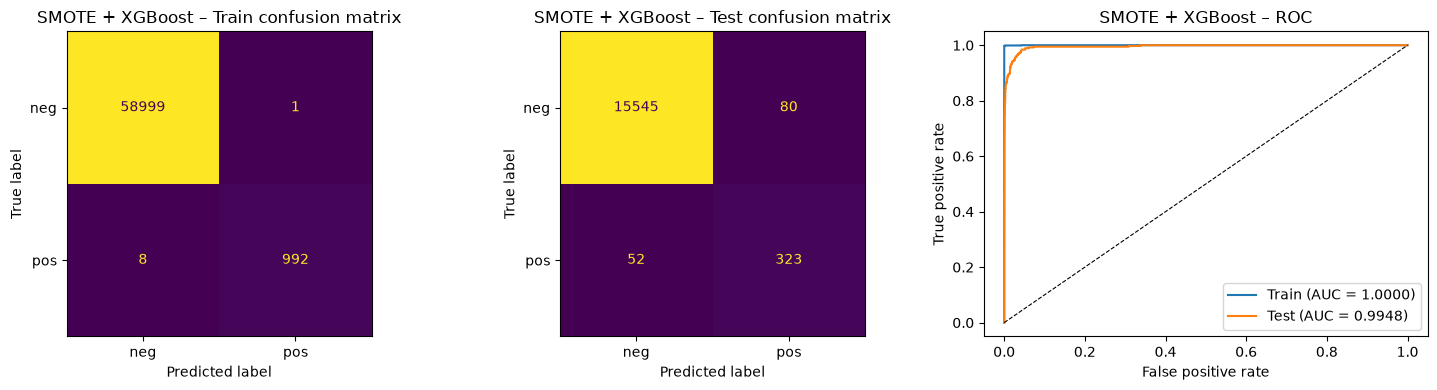

            TN    FP    FN     TP     AUC  Misclassification     Cost
Train  58999.0   1.0   8.0  992.0  1.0000            0.00015   4010.0
Test   15545.0  80.0  52.0  323.0  0.9948            0.00825  26800.0

5-fold CV error = 0.00673   |   Test error = 0.00825


In [21]:
smote_res = evaluate(gs_smote.best_estimator_, "SMOTE + XGBoost")
print(f"\n5-fold CV error = {smote_cv_err:.5f}   |   "
      f"Test error = {smote_res.loc['Test', 'Misclassification']:.5f}")

In [22]:
summary = pd.DataFrame({m: r.loc["Test"] for m, r in results.items()}).T
summary.index.name = "Test set"
print(summary.to_string())

                      TN     FP    FN     TP     AUC  Misclassification     Cost
Test set                                                                        
RF               15609.0   16.0  97.0  278.0  0.9944            0.00706  48660.0
Balanced RF      14773.0  852.0   6.0  369.0  0.9925            0.05362  11520.0
XGBoost          15606.0   19.0  85.0  290.0  0.9958            0.00650  42690.0
SMOTE + XGBoost  15545.0   80.0  52.0  323.0  0.9948            0.00825  26800.0


**Right-way CV.** SMOTE is applied only to the training folds inside each CV split (via the `imblearn` Pipeline), and every validation fold contains only original data. The resulting CV error (0.00673) and CV AUC (0.98802) are close to the test results (error 0.00825, AUC 0.9948), so the estimate is realistic. As in 1(e), the CV error is slightly lower because the test set has a higher positive rate. Applying SMOTE before splitting would leak information from synthetic points into the validation folds and give an over-optimistic estimate.

**Uncompensated vs. SMOTE XGBoost (test set).**

| | XGBoost (1e) | SMOTE + XGBoost (1f) |
|---|---|---|
| FN | 85 | **52** |
| FP | **19** | 80 |
| Misclassification | **0.00650** | 0.00825 |
| AUC | **0.9958** | 0.9948 |
| Scania cost | 42,690 | **26,800** |

SMOTE reduces missed failures (recall 77% → 86%) at the cost of more false alarms, so the misclassification rises slightly but the Scania cost drops by 37%. The AUC does not improve: SMOTE does not make the model rank positives better, it mainly shifts the decision boundary toward the positive class.

**Overall.** Among all models, the balanced RF has the lowest Scania cost (11,520) because it pushes recall the furthest (FN = 6). SMOTE only interpolates between existing positives, so positives unlike the training ones are likely still missed (FN = 52). XGBoost has the best ranking ability (highest AUC), so tuning its decision threshold toward the cost matrix could reduce its cost further.

## 2. ISLR 6.6.3

**(a) iv. Steadily decreases.** When $s=0$, all $\beta_j$ must be 0 and the model can only predict $\bar y$, so the fit is poorest. As $s$ increases, the coefficients get a larger budget and the optimizer can search a larger feasible set, so the minimized training RSS can only go down. Once $s$ is large enough that the constraint is no longer active, the solution is ordinary least squares and the training RSS stops changing (it converges). Overfitting never increases the training RSS; it only shows up on the test set.

**(b) ii. Decreases initially, then increases in a U shape.** When $s$ is too small the model underfits (high bias), so the test RSS is high. As $s$ grows the fit improves and the test RSS falls. When $s$ becomes too large the constraint no longer restrains the coefficients, the model starts to fit noise (overfitting), and the test RSS rises again.

**(c) iii. Steadily increases.** At $s=0$ the model always predicts $\bar y$, which barely changes from one training set to another, so the variance is minimal. As $s$ increases, the coefficients can follow the training data more closely, including its noise, so the fitted model changes more across training sets and the variance keeps increasing.

**(d) iv. Steadily decreases.** The larger the budget $s$, the more finely the model can approximate the true relationship, so the squared bias decreases (at the price of overfitting when $s$ is too large).

**(e) v. Remains constant.** The irreducible error $\text{Var}(\epsilon)$ cannot be removed by any model; it does not depend on the coefficients or on $s$.

## 3. ISLR 6.6.5

Let $x_{11}=x_{12}=A$, so $x_{21}=x_{22}=-A$; also $y_2=-y_1$ and $\hat\beta_0=0$.

**(a) Ridge optimization problem:**
$$\min_{\beta_1,\beta_2}\;(y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(\beta_1^2+\beta_2^2)$$
The second residual equals minus the first one, so the objective simplifies to
$$2\big(y_1-A(\beta_1+\beta_2)\big)^2+\lambda(\beta_1^2+\beta_2^2).$$

**(b) $\hat\beta_1=\hat\beta_2$.** Setting the partial derivatives to zero:
$$-4A\big(y_1-A(\beta_1+\beta_2)\big)+2\lambda\beta_1=0,\qquad -4A\big(y_1-A(\beta_1+\beta_2)\big)+2\lambda\beta_2=0.$$
The first terms are identical, so subtracting gives $2\lambda(\beta_1-\beta_2)=0$, i.e. $\hat\beta_1=\hat\beta_2$ for $\lambda>0$ (explicitly $\hat\beta_1=\hat\beta_2=\frac{2Ay_1}{4A^2+\lambda}$).
Intuitively, the RSS depends only on $\beta_1+\beta_2$, and for a fixed sum $\beta_1^2+\beta_2^2$ is smallest when the sum is split equally.

**(c) Lasso optimization problem:**
$$\min_{\beta_1,\beta_2}\;(y_1-\beta_1x_{11}-\beta_2x_{12})^2+(y_2-\beta_1x_{21}-\beta_2x_{22})^2+\lambda(|\beta_1|+|\beta_2|)$$
which simplifies to $2\big(y_1-A(\beta_1+\beta_2)\big)^2+\lambda(|\beta_1|+|\beta_2|)$.

**(d) The lasso solutions are not unique.** The RSS term depends only on $c=\beta_1+\beta_2$, and $|\beta_1|+|\beta_2|\ge|c|$ with equality iff $\beta_1,\beta_2$ have the same sign. So once the optimal sum $\hat c$ is fixed (for $\hat c>0$), every point of the segment
$$\{\beta_1+\beta_2=\hat c,\;\beta_1\ge0,\;\beta_2\ge0\}$$
gives the same minimal objective value, i.e. there are infinitely many solutions (for $\hat c<0$ the analogous segment with $\beta_1,\beta_2\le0$).
Geometrically, the RSS contours are lines $\beta_1+\beta_2=\text{const}$, parallel to an edge of the lasso diamond $|\beta_1|+|\beta_2|\le s$, so they touch the diamond along a whole edge rather than at a single point.

## 4. ISLR 8.4.5

The ten estimates of $P(\text{Red}\mid X)$ are 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75.

- **Majority vote:** 6 of the 10 estimates exceed 0.5 (6 votes for Red vs. 4 for Green), so the classification is **Red**.
- **Average probability:** $\bar p = 4.5/10 = 0.45 < 0.5$, so the classification is **Green**.

The two approaches disagree because majority voting ignores how confident each vote is. The four Green votes are very confident ($P(\text{Green}) = 0.8$–$0.9$), whereas most Red votes are only slightly above 0.5. Averaging the probabilities keeps this information and gives a smoother decision.

## 5. ISLR 9.7.3

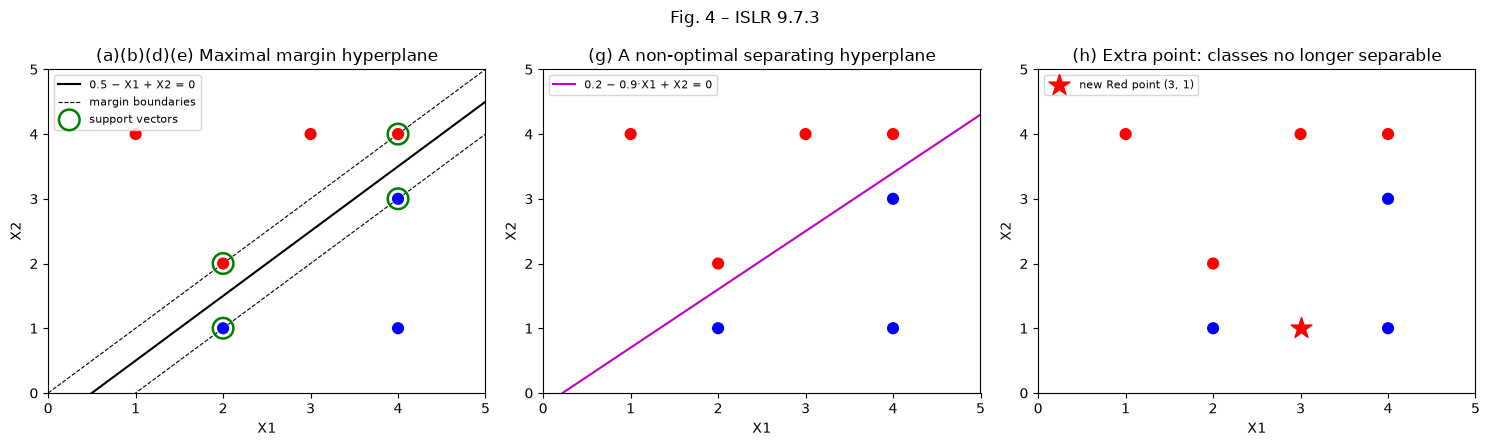

In [23]:
X1 = np.array([3, 2, 4, 1, 2, 4, 4])
X2 = np.array([4, 2, 4, 4, 1, 3, 1])
colors = ["red"] * 4 + ["blue"] * 3
xs = np.linspace(0, 5, 100)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
titles = ["(a)(b)(d)(e) Maximal margin hyperplane",
          "(g) A non-optimal separating hyperplane",
          "(h) Extra point: classes no longer separable"]
for ax, t in zip(axes, titles):
    ax.scatter(X1, X2, c=colors, s=60, zorder=3)
    ax.set(xlim=(0, 5), ylim=(0, 5), xlabel="X1", ylabel="X2", title=t)

# (b)(d)(e)
ax = axes[0]
ax.plot(xs, xs - 0.5, "k-", label="0.5 − X1 + X2 = 0")
ax.plot(xs, xs, "k--", lw=0.8, label="margin boundaries")
ax.plot(xs, xs - 1, "k--", lw=0.8)
sv = np.array([[2, 2], [4, 4], [2, 1], [4, 3]])
ax.scatter(sv[:, 0], sv[:, 1], s=220, facecolors="none", edgecolors="green", lw=1.8,
           label="support vectors", zorder=4)
ax.legend(loc="upper left", fontsize=8)

# (g)
axes[1].plot(xs, 0.9 * xs - 0.2, "m-", label="0.2 − 0.9·X1 + X2 = 0")
axes[1].legend(loc="upper left", fontsize=8)

# (h)
axes[2].scatter([3], [1], c="red", marker="*", s=250, zorder=4, label="new Red point (3, 1)")
axes[2].legend(loc="upper left", fontsize=8)

fig.suptitle("Fig. 4 – ISLR 9.7.3")
plt.tight_layout(); plt.show()

**(a)** The seven observations are plotted in Fig. 4.

**(b)** The closest Red and Blue points are (2,2)/(2,1) and (4,4)/(4,3). The Red pair lies on $X_2 = X_1$ and the Blue pair on $X_2 = X_1 - 1$. The optimal separating hyperplane runs halfway between these two parallel lines, through (2, 1.5) and (4, 3.5):
$$X_2 = X_1 - 0.5 \quad\Longleftrightarrow\quad 0.5 - X_1 + X_2 = 0.$$

**(c)** Classify to **Red** if $0.5 - X_1 + X_2 > 0$, and to **Blue** otherwise. So $\beta_0 = 0.5$, $\beta_1 = -1$, $\beta_2 = 1$.

**(d)** The margin boundaries are the dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$ (left panel). The margin (distance from the hyperplane to each boundary) is $\dfrac{0.5}{\sqrt{1^2+1^2}} = \dfrac{\sqrt2}{4} \approx 0.354$.

**(e)** The support vectors are the four points on the margin boundaries: (2,2) and (4,4) (Red), and (2,1) and (4,3) (Blue), circled in green.

**(f)** Observation 7, (4,1), is at distance $\frac{|0.5 - 4 + 1|}{\sqrt2} \approx 1.77$ from the hyperplane, well outside the margin. It is not a support vector, and the maximal margin hyperplane depends only on the support vectors. Hence a slight movement of this point (as long as it does not enter the margin) does not change the hyperplane.

**(g)** For example, $0.2 - 0.9X_1 + X_2 = 0$ (middle panel, magenta) still separates the two classes, but its closest points, (2,2) and (4,3), are only $\frac{0.4}{\sqrt{0.9^2+1^2}} \approx 0.297$ away. This is less than the optimal margin of 0.354, so it is not the maximal margin hyperplane.

**(h)** Adding a **Red** observation at **(3, 1)** (right panel, star) makes the classes non-separable. This point lies on the segment between the Blue points (2,1) and (4,1). Any line that puts both of these on the Blue side also puts the whole segment between them, including (3,1), on the Blue side.

**References**
1. James, Witten, Hastie & Tibshirani, *An Introduction to Statistical Learning*, 2nd ed.
2. Chen, Liaw & Breiman (2004), *Using Random Forest to Learn Imbalanced Data*, UC Berkeley Tech. Report 666.
3. Chawla et al. (2002), *SMOTE: Synthetic Minority Over-sampling Technique*, JAIR 16.
4. scikit-learn: https://scikit-learn.org/stable/modules/impute.html
5. imbalanced-learn: https://imbalanced-learn.org/stable/
6. XGBoost parameters: https://xgboost.readthedocs.io/en/stable/parameter.html
7. Course forum clarification on 1(e): standard XGBoost with L1 regularization is sufficient.